# Analyse du domaine santé

On part des fichiers nettoyés dans `03_health_nettoyage.ipynb`. On regarde d'abord les mesures des patients, on laisse les statistiques nous dire ce qui sort du lot, puis on regarde de plus près les patients concernés. On garde aussi les pistes qui ne donnent rien.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from itertools import combinations
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import LocalOutlierFactor
from sklearn.ensemble import IsolationForest
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

DOSSIER = Path("data_clean/health")
patients = pd.read_csv(DOSSIER / "patient_administration.csv", parse_dates=["date_of_birth"])
observations = pd.read_csv(DOSSIER / "clinical_observations.csv", parse_dates=["observation_time"])
procedures = pd.read_csv(DOSSIER / "clinical_procedures.csv")
notes = pd.read_csv(DOSSIER / "clinical_notes.csv")
enregistrements = pd.read_csv(DOSSIER / "cardiac_recordings.csv")
signaux = pd.read_csv(DOSSIER / "cardiac_signal_samples.csv")

patients["nom"] = patients["given_name"] + " " + patients["family_name"]
infos = patients.set_index("patient_number")[["nom", "occupation_text"]]

## 1. Que contient chaque fichier ?

- `patient_administration` : l'identité des 240 patients (nom, date de naissance, région, profession).
- `clinical_encounters` : les consultations.
- `clinical_observations` : les mesures prises pendant les consultations. Le résultat est soit un nombre (`numeric_value`), soit un mot (`text_value`). La colonne `interpretation_code` dit si la mesure est jugée normale, à revoir ou incohérente.
- `clinical_procedures` : les actes médicaux réalisés.
- `clinical_notes` : les notes écrites par les médecins.
- `cardiac_recordings` : une ligne par enregistrement du cœur (patient, date, appareil).
- `cardiac_signal_samples` : la courbe de chaque enregistrement, point par point, avec deux capteurs (canal a et canal b).

On commence par les mesures, qui sont le plus gros fichier. On liste les 32 mesures avec leur nom complet.

In [2]:
observations.groupby("observation_code").agg(
    nom_complet=("observation_name", "first"),
    unite=("unit", "first"),
    plage_attendue=("reference_range_text", "first"),
    nombre_de_mesures=("observation_number", "count"))

,nom_complet,unite,plage_attendue,nombre_de_mesures
observation_code,,,,
AGECOND,age-related condition count,count,0–10,240
APICAL,apical cardiac rate,bpm,50–110,1017
BALANCE,balance score,index,0–100,947
BINOCOORD,binocular coordination,NaN,normal; reduced; atypical; not tested,240
BIOAGE,estimated biological age,years,18–100,934
CAMMATCH,camera match confidence,index,0–100,240
CARDOUT,estimated cardiac output,l/min,3.5–8.0,941
COGNITIVE,cognitive score,index,0–100,948
CVRISK,cardiovascular risk score,index,0–100,240


## 2. Une ligne par patient

Chaque patient apparaît sur des dizaines de lignes, une par mesure. Pour comparer les patients, on fait un tableau avec une ligne par patient et une colonne par mesure. Quand un patient a été mesuré plusieurs fois, on garde la moyenne.

In [3]:
tableau = observations.pivot_table(index="patient_number", columns="observation_code",
                                   values="numeric_value", aggfunc="mean")
print(tableau.shape)
tableau.head()

(240, 27)


observation_code,AGECOND,APICAL,BALANCE,BIOAGE,CAMMATCH,CARDOUT,COGNITIVE,CVRISK,DIABP,GAITSYM,...,RIGHTEYE,RPULSE,STROKEVOL,SYSBP,THERMQUAL,THORPEAK,THORVIB,VALEFT,VARIGHT,WALKSPD
patient_number,,,,,,,,,,,,,,,,,,,,,
PAT-31001,0.0,89.100000,92.750000,20.625000,87.5,5.615000,84.475000,43.9,55.0,87.0,...,16.0,66.325000,78.6,131.4,98.0,24.225000,31.30,0.91,0.78,1.11
PAT-31002,2.0,91.500000,74.475000,49.720000,78.6,5.940000,88.900000,36.9,75.5,75.4,...,6.2,73.920000,49.5,110.4,88.5,32.750000,31.02,0.78,0.97,1.17
PAT-31003,0.0,85.560000,79.700000,58.940000,93.7,6.198000,88.566667,68.0,69.4,87.6,...,-3.4,77.740000,78.7,140.2,81.4,49.020000,17.88,0.94,0.97,1.14
PAT-31004,1.0,76.633333,78.433333,75.833333,86.6,3.690000,98.766667,45.4,73.8,97.0,...,5.0,56.533333,63.2,121.6,90.3,19.166667,42.50,0.95,0.89,1.40
PAT-31005,1.0,60.850000,79.100000,48.275000,92.8,4.356667,87.333333,38.3,72.6,96.9,...,-1.8,66.475000,83.8,115.3,86.3,34.766667,34.70,0.91,0.98,1.12


On a 240 patients et 27 mesures numériques. Les 5 autres mesures donnent un mot : on les traite à part.

## 3. Les valeurs nominales

Deux informations sont des catégories et pas des nombres :
- le résultat de 5 mesures (yeux, équilibre, muscles, système nerveux), qui vaut par exemple « normal » ou « atypical » ;
- le jugement porté sur chaque mesure (`interpretation_code`).

On regarde les catégories qui existent.

In [4]:
textuelles = observations[observations["text_value"].notna()]
pd.crosstab(textuelles["observation_code"], textuelles["text_value"])

text_value,abnormal,atypical,inconclusive,mild,none,normal,reduced
observation_code,,,,,,,
BINOCOORD,0,14,0,0,0,148,78
MUSC,0,0,0,87,153,0,0
NEURO,0,0,0,70,170,0,0
OCULAR,0,42,455,0,0,413,0
VESTIB,11,0,60,0,0,169,0


In [5]:
observations["interpretation_code"].value_counts()

interpretation_code
within_expected_range    12111
recorded                  5188
review                     326
discordant                 109
Name: count, dtype: int64

- Les résultats « atypical » et « abnormal » sont rares.
- La plupart des mesures sont jugées normales ; quelques-unes sont « à revoir » (`review`) ou « incohérentes » (`discordant`).

Plutôt que de créer une colonne par catégorie, on résume chaque patient par deux parts, qu'on ajoute au tableau :
- la part de ses résultats « atypical » ou « abnormal » ;
- la part de ses mesures jugées « à revoir » ou « incohérentes ».

In [6]:
textuelles = textuelles.assign(atypique=textuelles["text_value"].isin(["atypical", "abnormal"]))
tableau["part_atypique"] = textuelles.groupby("patient_number")["atypique"].mean()

a_revoir = observations["interpretation_code"].isin(["review", "discordant"])
tableau["part_a_revoir"] = a_revoir.groupby(observations["patient_number"]).mean()

print("Corrélation entre les deux parts :", round(tableau["part_atypique"].corr(tableau["part_a_revoir"]), 2))
tableau[["part_atypique", "part_a_revoir"]].describe().round(2)

Corrélation entre les deux parts : 0.58


observation_code,part_atypique,part_a_revoir
count,240.00,240.00
mean,0.03,0.02
std,0.12,0.05
min,0.00,0.00
25%,0.00,0.00
50%,0.00,0.00
75%,0.00,0.02
max,0.67,0.23


- La plupart des patients n'ont aucun résultat atypique, mais quelques-uns en ont beaucoup.
- Les deux parts sont liées : les patients avec des résultats atypiques ont aussi plus de mesures à revoir.

## 4. Les valeurs numériques : quelles mesures sortent du lot ?

Pour chaque mesure, on applique la règle de l'IQR et on compte les patients très éloignés des autres. On inclut les deux parts qu'on vient de calculer.

In [7]:
q1, q3 = tableau.quantile(0.25), tableau.quantile(0.75)
iqr = q3 - q1
hors_norme = ((tableau < q1 - 1.5 * iqr) | (tableau > q3 + 1.5 * iqr)).sum().sort_values(ascending=False)
noms = observations.groupby("observation_code")["observation_name"].first()
hors_norme.to_frame("patients hors norme").join(noms).head(14)

,patients hors norme,observation_name
observation_code,,
part_a_revoir,36,NaN
part_atypique,28,NaN
LEFTEYE,15,left-eye deviation
LATSWAY,13,lateral sway index
IDCONS,12,identity consistency score
RIGHTEYE,11,right-eye deviation
CAMMATCH,9,camera match confidence
GAITSYM,7,gait symmetry index
THORVIB,6,thoracic vibration index


- Les mesures de santé courantes (tension, oxygène, vue) n'ont presque pas de valeurs hors norme.
- Les mesures qui en ont le plus sont : les deux parts nominales, la déviation des yeux, l'oscillation à la marche, la cohérence d'identité, la reconnaissance par caméra, la symétrie de la marche, les vibrations de la poitrine et le débit cardiaque.

On regarde leur distribution.

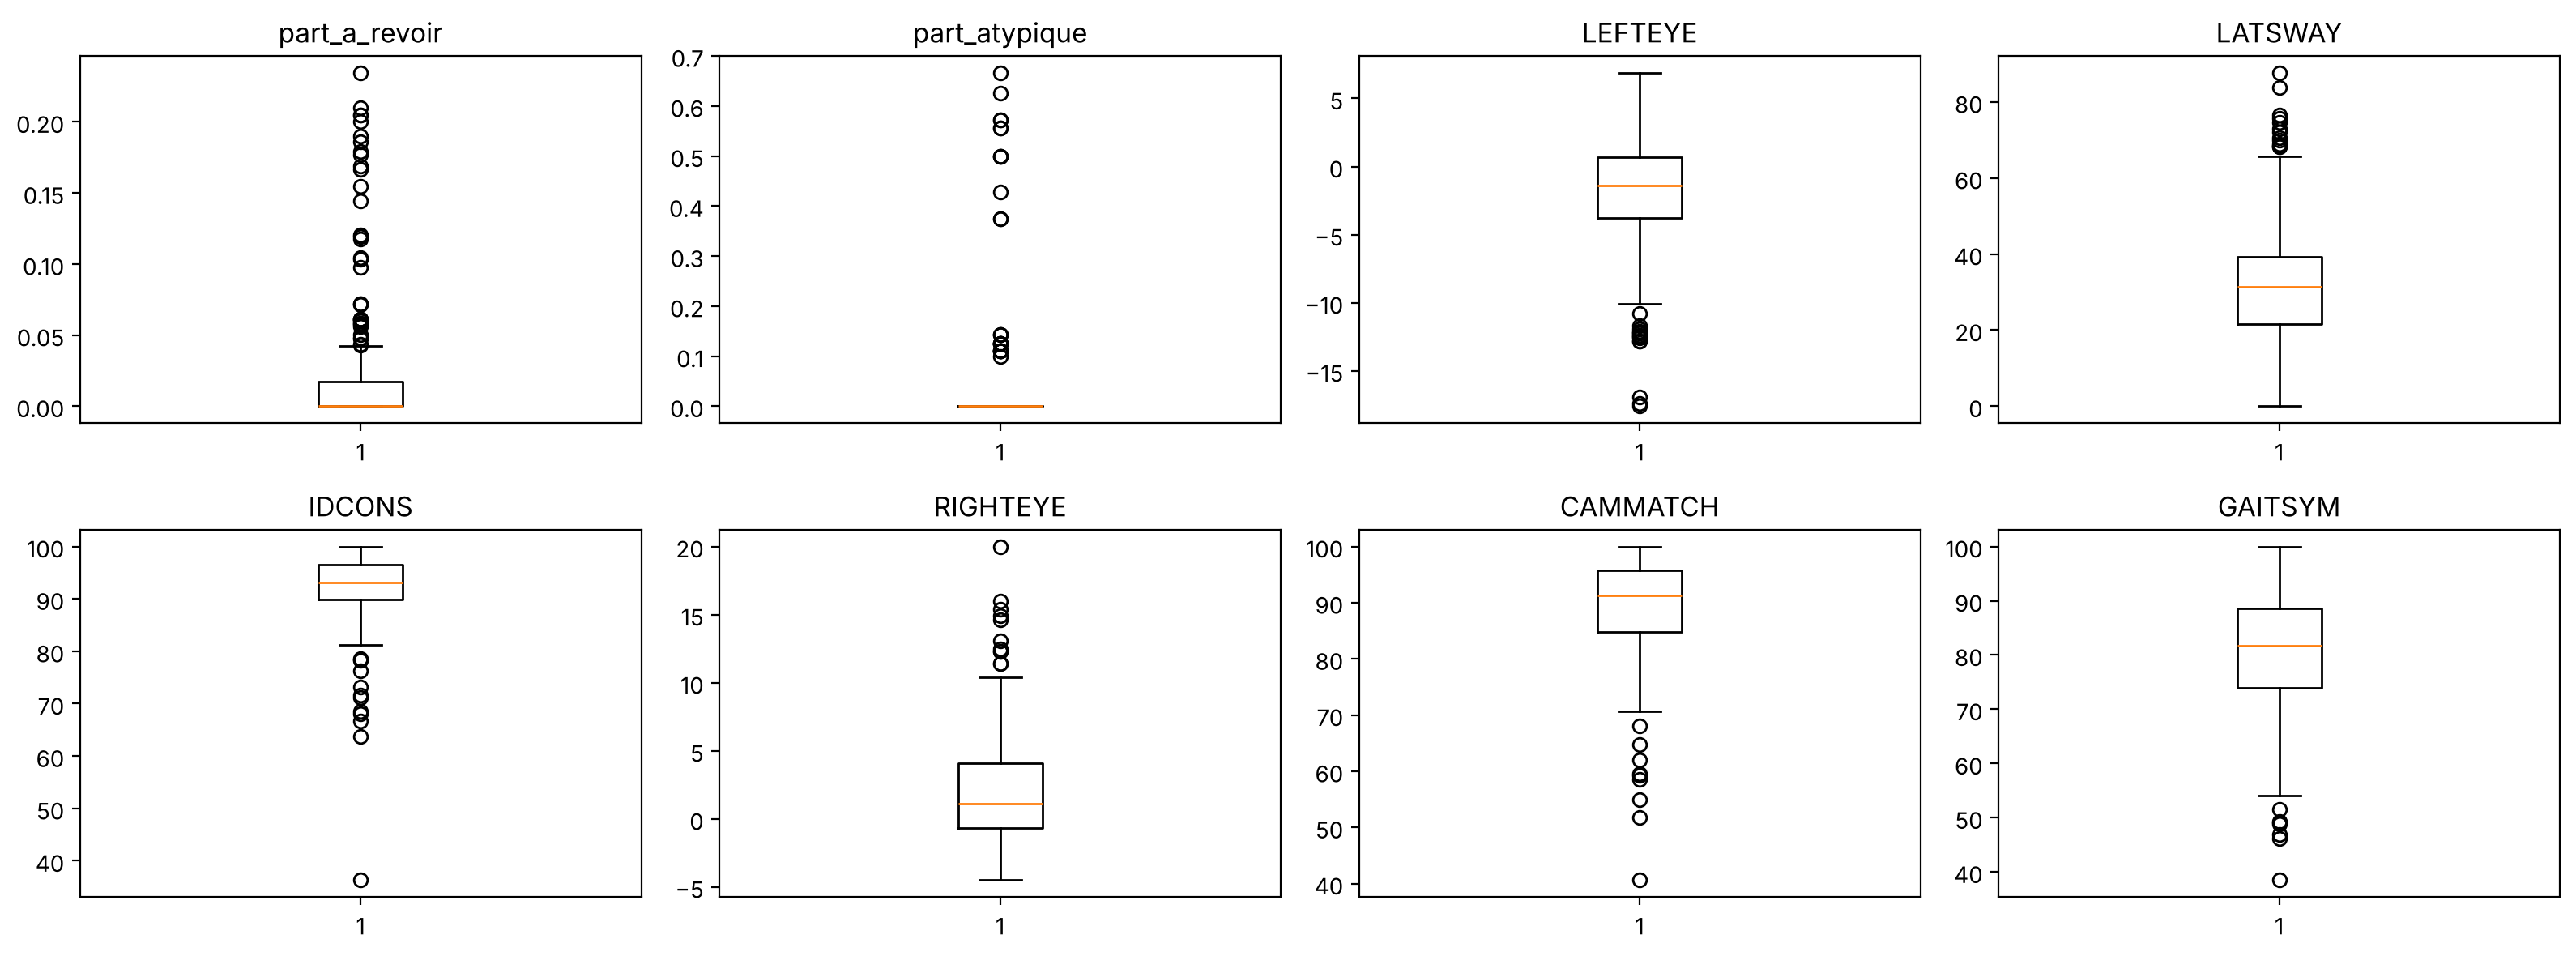

In [8]:
a_voir = hors_norme.head(8).index
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, m in zip(axes.ravel(), a_voir):
    ax.boxplot(tableau[m].dropna())
    ax.set_title(m)
plt.tight_layout()
plt.show()

Pour `IDCONS` et `CAMMATCH`, les points isolés sont tous en bas : quelques patients sont mal reconnus par les systèmes d'identification.

### Une erreur d'appareil ?

On vérifie si ces valeurs viennent de mesures de mauvaise qualité.

In [9]:
observations["quality_code"].value_counts()

quality_code
acceptable    17734
Name: count, dtype: int64

Toutes les mesures sont de qualité « acceptable ». Piste sans issue : ce ne sont pas des erreurs d'appareil.

## 5. Est-ce toujours les mêmes patients ?

On garde les mesures qui ont au moins 6 patients hors norme, et on cherche les patients qui sont atypiques sur plusieurs d'entre elles à la fois. Les mesures n'ont pas la même unité : on les met d'abord à la même échelle.

In [10]:
mesures = hors_norme[hors_norme >= 6].index.tolist()
print(mesures)

X = tableau[mesures].fillna(tableau[mesures].median())   # quelques valeurs manquantes : on met la médiane
X_std = StandardScaler().fit_transform(X)

['part_a_revoir', 'part_atypique', 'LEFTEYE', 'LATSWAY', 'IDCONS', 'RIGHTEYE', 'CAMMATCH', 'GAITSYM', 'THORVIB', 'CARDOUT']


### Premier essai : le LOF

Le LOF juge un patient atypique s'il a peu de voisins proches.

In [11]:
lof = LocalOutlierFactor(n_neighbors=20).fit(X_std)
score_lof = pd.Series(-lof.negative_outlier_factor_, index=X.index, name="score_lof")
score_lof.sort_values(ascending=False).head(10).round(2).to_frame().join(infos)

,score_lof,nom,occupation_text
patient_number,,,
PAT-31081,2.29,Orin Kerin,compliance counsel
PAT-31039,2.24,Liora Uren,senior field analyst
PAT-31163,2.18,Gita Corda,research assistant
PAT-31139,2.04,Kira Havel,retired professional
PAT-31007,2.02,Marek Kerin,wildlife programme officer
PAT-31031,1.98,Daria Aster,teacher
PAT-31152,1.96,Celia Wessen,small-business owner
PAT-31012,1.85,Amara Sen,research professional
PAT-31233,1.85,Mara Ven,research professional


Les patients en tête sont très variés. Quelques noms qu'on retrouvera plus loin apparaissent, mais mélangés à d'autres profils sans point commun. Si les patients atypiques se ressemblent entre eux, ils sont voisins les uns des autres, et le LOF ne les voit pas comme isolés. Piste peu concluante.

### Deuxième essai : l'Isolation Forest

L'Isolation Forest cherche les patients faciles à séparer de la masse, même s'ils forment un petit groupe.

In [12]:
def isolation(colonnes):
    Z = StandardScaler().fit_transform(tableau[colonnes].fillna(tableau[colonnes].median()))
    score = -IsolationForest(random_state=0).fit(Z).score_samples(Z)
    return pd.Series(score, index=tableau.index).sort_values(ascending=False)

score = isolation(mesures)
score.head(15).round(3).to_frame("score").join(infos)

,score,nom,occupation_text
patient_number,,,
PAT-31233,0.691,Mara Ven,research professional
PAT-31065,0.671,Corin Hallen,clinical specialist
PAT-31037,0.651,Sel Aran,research professional
PAT-31152,0.638,Celia Wessen,small-business owner
PAT-31162,0.636,Eli Varen,corporate adviser
PAT-31040,0.629,Jonah Valen,research professional
PAT-31186,0.621,Soren Kader,corporate adviser
PAT-31086,0.596,Niko Veran,corporate adviser
PAT-31012,0.594,Amara Sen,research professional


Les premiers patients ont surtout des profils proches (conseillers, chercheurs, spécialistes cliniques). On garde les 11 premiers.

### Le résultat dépend-il du choix des mesures ?

On a choisi les mesures avec au moins 6 patients hors norme. On refait le calcul avec d'autres choix pour voir si on retrouve les mêmes patients.

In [13]:
groupe = score.index[:11]
for seuil in [4, 5]:
    autre = isolation(hors_norme[hors_norme >= seuil].index.tolist()).index[:11]
    print(f"Mesures avec au moins {seuil} patients hors norme : {len(set(autre) & set(groupe))} patients sur 11 en commun")
autre = isolation(tableau.columns.tolist()).index[:11]
print(f"Toutes les mesures : {len(set(autre) & set(groupe))} patients sur 11 en commun")

Mesures avec au moins 4 patients hors norme : 11 patients sur 11 en commun
Mesures avec au moins 5 patients hors norme : 11 patients sur 11 en commun


Toutes les mesures : 10 patients sur 11 en commun


On retrouve presque toujours les mêmes patients : le groupe ne dépend pas de notre choix de mesures.

### Qu'est-ce qui les distingue ?

On compare ce groupe aux autres patients sur **toutes** les mesures, à la même échelle. Une différence de 1 correspond à un écart habituel entre patients ; au-delà de 2, c'est très grand.

In [14]:
tout_std = pd.DataFrame(StandardScaler().fit_transform(tableau.fillna(tableau.median())),
                        index=tableau.index, columns=tableau.columns)
difference = tout_std.loc[groupe].mean() - tout_std.drop(groupe).mean()
difference.sort_values(key=abs, ascending=False).head(10).round(1).to_frame("différence").join(noms)

,différence,observation_name
observation_code,,
part_a_revoir,3.4,NaN
part_atypique,3.3,NaN
IDCONS,-2.3,identity consistency score
CARDOUT,2.1,estimated cardiac output
CAMMATCH,-2.0,camera match confidence
THORVIB,1.9,thoracic vibration index
THORPEAK,1.8,thoracic secondary peak index
APICAL,1.7,apical cardiac rate
LATSWAY,1.6,lateral sway index


Par rapport aux autres, ces 11 patients ont :
- beaucoup plus de résultats atypiques et de mesures à revoir ;
- une identification par caméra beaucoup moins fiable ;
- plus de vibrations et de pics dans la poitrine ;
- un débit cardiaque et un rythme au cœur (`APICAL`) plus élevés.

Le dernier point est étrange. On compare le rythme pris au cœur et le pouls pris au poignet, qui devraient compter les mêmes battements.

In [15]:
pouls = tableau[["APICAL", "PPULSE"]].copy()
pouls["groupe"] = np.where(pouls.index.isin(groupe), "11 patients atypiques", "autres patients")
pouls.groupby("groupe").mean().round(1)

observation_code,APICAL,PPULSE
groupe,,
11 patients atypiques,94.7,74.6
autres patients,75.5,73.0


Chez les autres patients, les deux sont proches. Chez les 11 patients, le cœur bat environ 20 fois de plus par minute que le pouls au poignet, comme si une partie des battements n'arrivait pas au poignet.

On visualise le groupe avec une ACP, qui résume les mesures sur deux axes.

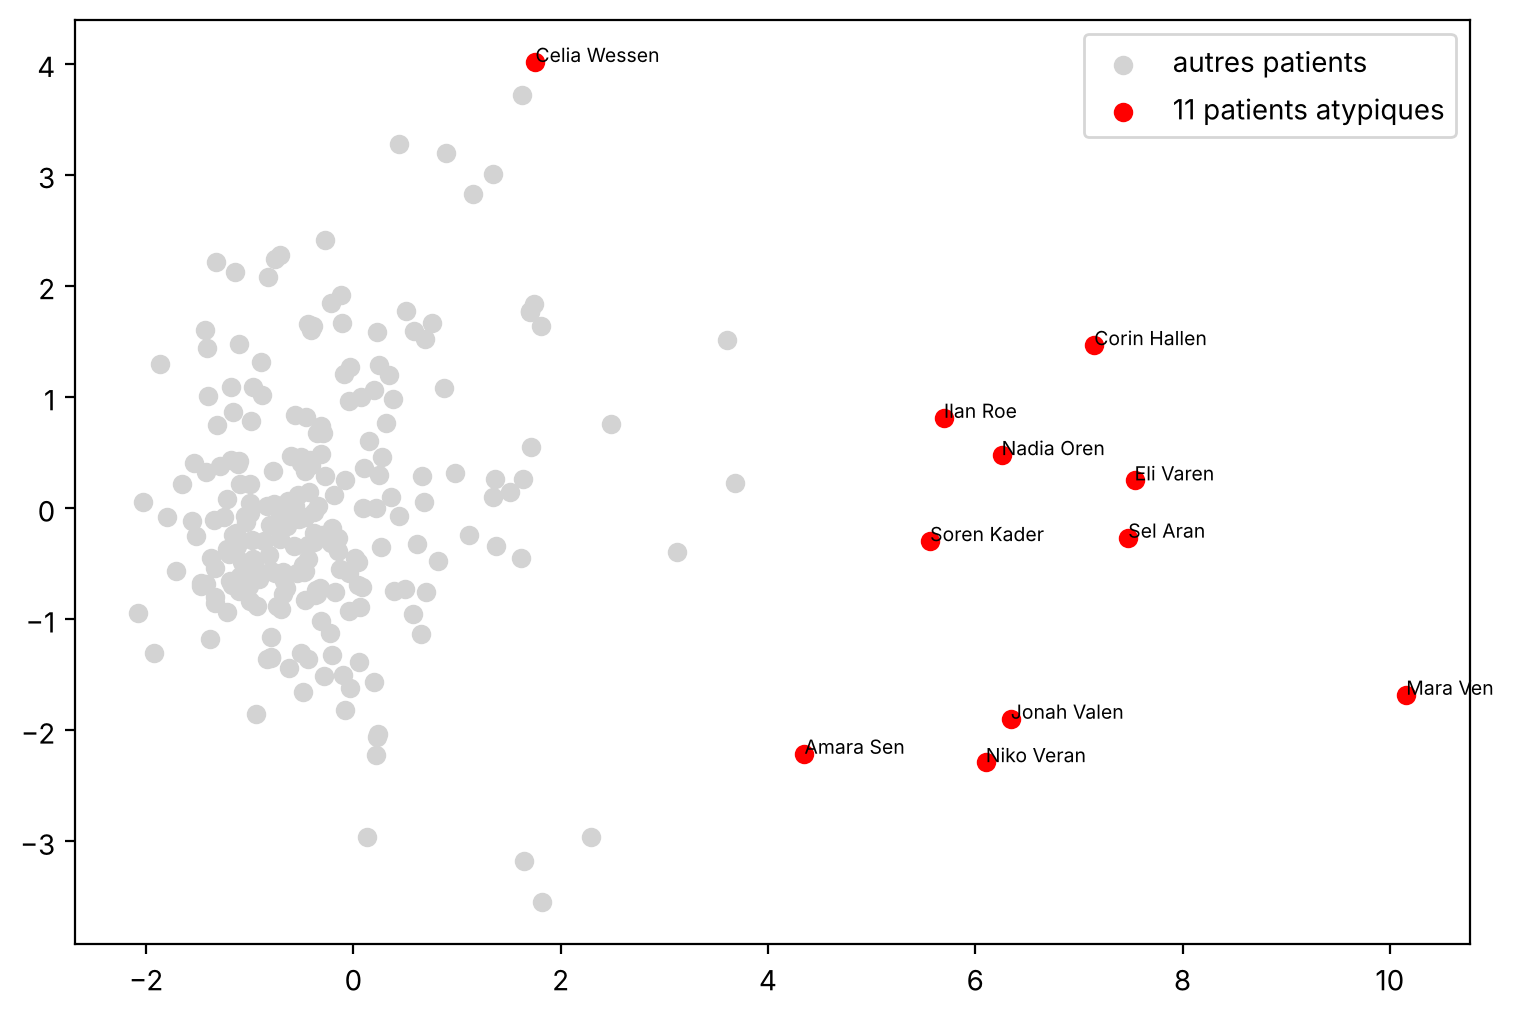

In [16]:
coords = PCA(n_components=2).fit_transform(X_std)
rouge = X.index.isin(groupe)
plt.figure(figsize=(9, 6))
plt.scatter(coords[~rouge, 0], coords[~rouge, 1], c="lightgray", label="autres patients")
plt.scatter(coords[rouge, 0], coords[rouge, 1], c="red", label="11 patients atypiques")
for i in np.where(rouge)[0]:
    plt.annotate(infos.loc[X.index[i], "nom"], coords[i], fontsize=7)
plt.legend()
plt.show()

Les 11 patients sont regroupés à l'écart des autres : ils forment bien un groupe à part.

## 6. On regarde ces patients de plus près

Maintenant qu'on a un groupe, on cherche ce que les autres fichiers disent sur eux : leurs actes médicaux, leurs enregistrements du cœur et les notes des médecins.

### Leurs actes médicaux

In [17]:
procedures[procedures["patient_number"].isin(groupe)]["procedure_code"].value_counts()

procedure_code
AGE-PNL     3
OCC-PNL     3
CARD-IMG    3
AUT-REV     3
OCT-TRK     2
MOB-PNL     1
Name: count, dtype: int64

Ce sont des examens courants (bilans, imagerie cardiaque, suivi des yeux). Rien de particulier de ce côté.

### Leurs enregistrements du cœur

Le cœur bat plus vite que le pouls chez ces patients. Les enregistrements du cœur ont deux capteurs : s'ils écoutent le même cœur, ils doivent battre au même rythme.

Pour trouver le rythme d'un signal, on utilise l'autocorrélation : on compare le signal avec lui-même décalé dans le temps. Le décalage où il se ressemble le plus donne la durée d'un battement.

In [18]:
def rythme(signal, frequence):
    x = signal - signal.mean()
    ressemblance = np.correlate(x, x, "full")[len(x) - 1:] / (x @ x)
    debut, fin = int(frequence * 0.25), int(frequence * 2)   # entre 30 et 240 battements par minute
    k = np.argmax(ressemblance[debut:fin])
    return round(60 * frequence / (debut + k)), round(ressemblance[debut + k], 2)

resultats = []
for rid, g in signaux.sort_values("time_ms").groupby("recording_id"):
    frequence = 1000 / g["time_ms"].diff().median()
    rythme_a, regularite_a = rythme(g["channel_a_normalized"].values, frequence)
    rythme_b, regularite_b = rythme(g["channel_b_normalized"].values, frequence)
    resultats.append({"recording_id": rid, "rythme_a": rythme_a, "rythme_b": rythme_b,
                      "regularite_a": regularite_a, "regularite_b": regularite_b})

coeur = (pd.DataFrame(resultats)
         .merge(enregistrements[["recording_id", "patient_number"]], on="recording_id")
         .join(infos, on="patient_number"))
coeur["ecart_rythme"] = (coeur["rythme_a"] - coeur["rythme_b"]).abs()

# On garde les signaux réguliers (sinon le rythme calculé n'a pas de sens) avec deux rythmes nettement différents
deux_rythmes = coeur[(coeur["regularite_a"] > 0.7) & (coeur["regularite_b"] > 0.7) & (coeur["ecart_rythme"] > 10)]
deux_rythmes.assign(dans_le_groupe=deux_rythmes["patient_number"].isin(groupe))

,recording_id,rythme_a,rythme_b,regularite_a,regularite_b,patient_number,nom,occupation_text,ecart_rythme,dans_le_groupe
4,CRD-410005,67,100,0.79,0.80,PAT-31065,Corin Hallen,clinical specialist,33,True
13,CRD-410014,74,90,0.82,0.81,PAT-31233,Mara Ven,research professional,16,True
18,CRD-410019,71,88,0.78,0.80,PAT-31162,Eli Varen,corporate adviser,17,True
21,CRD-410022,71,97,0.78,0.78,PAT-31037,Sel Aran,research professional,26,True
24,CRD-410025,80,99,0.78,0.76,PAT-31040,Jonah Valen,research professional,19,True
30,CRD-410031,70,87,0.75,0.71,PAT-31162,Eli Varen,corporate adviser,17,True
37,CRD-410038,66,99,0.79,0.81,PAT-31065,Corin Hallen,clinical specialist,33,True


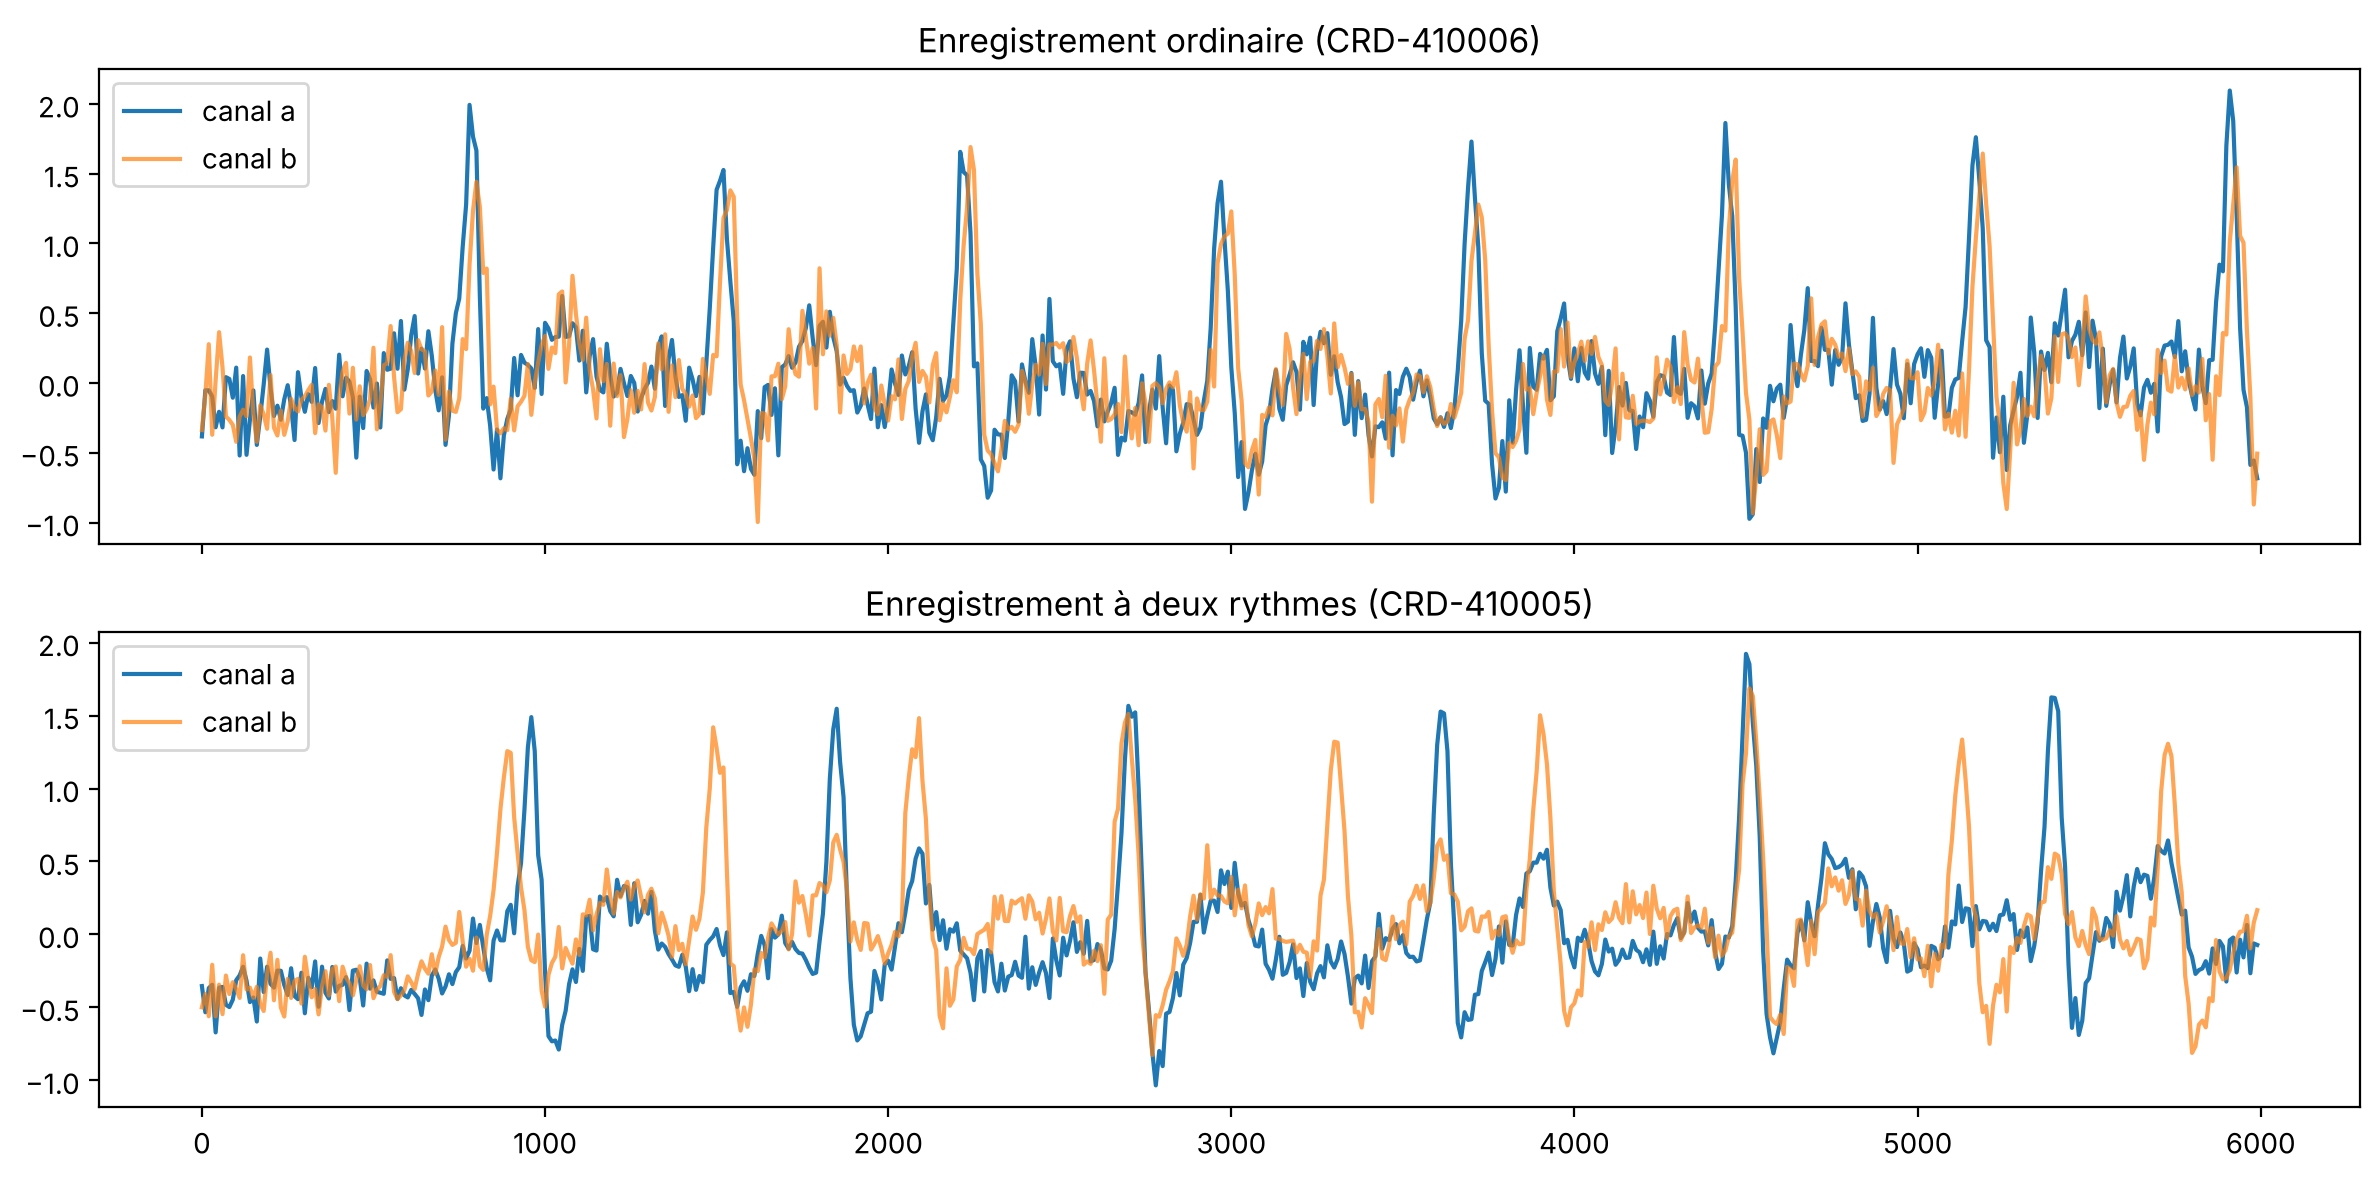

In [19]:
ordinaire = coeur[(coeur["regularite_a"] > 0.7) & (coeur["ecart_rythme"] == 0)]["recording_id"].iloc[0]
double = deux_rythmes["recording_id"].iloc[0]
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ax, rid, titre in [(axes[0], ordinaire, "Enregistrement ordinaire"),
                       (axes[1], double, "Enregistrement à deux rythmes")]:
    g = signaux[signaux["recording_id"] == rid].sort_values("time_ms").head(600)
    ax.plot(g["time_ms"], g["channel_a_normalized"], label="canal a")
    ax.plot(g["time_ms"], g["channel_b_normalized"], label="canal b", alpha=0.7)
    ax.set_title(f"{titre} ({rid})")
    ax.legend()
plt.tight_layout()
plt.show()

- Sur 44 enregistrements, 7 ont deux rythmes nettement différents.
- Ils appartiennent à 5 patients, tous dans le groupe des 11.
- Sur le graphique, les deux canaux d'un enregistrement ordinaire battent ensemble ; ceux d'un enregistrement à deux rythmes se décalent peu à peu.

Chaque capteur semble suivre un cœur différent.

### Les notes des médecins

Il y a 30 notes. Comme pour les rapports de terrain en écologie, on cherche celles qui ne ressemblent à aucune autre, avec TF-IDF et la similarité cosinus.

In [20]:
mots = TfidfVectorizer(stop_words="english").fit_transform(notes["text"])
similarite = cosine_similarity(mots)
np.fill_diagonal(similarite, np.nan)
notes["plus_proche_voisin"] = np.nanmax(similarite, axis=1).round(2)
notes["dans_le_groupe"] = notes["patient_number"].isin(groupe)
notes.sort_values("plus_proche_voisin")[["document_id", "patient_number", "title",
                                         "plus_proche_voisin", "dans_le_groupe"]].head(8)

,document_id,patient_number,title,plus_proche_voisin,dans_le_groupe
0,CLN-510027,PAT-31065,Targeted Thoracic Imaging Review,0.18,True
2,CLN-510025,PAT-31065,Restricted Phenotype and Public-Identity Resol...,0.19,True
1,CLN-510055,PAT-31115,Consultation on Recurrent Capture Discrepancies,0.20,True
3,CLN-510064,PAT-31012,Persistent Multisystem Follow-up,0.22,True
9,CLN-510081,PAT-31074,Clinical Summary 06,0.68,False
10,CLN-510126,PAT-31099,Thoracic Imaging Report 07,0.69,False
25,CLN-510093,PAT-31222,Occupational Health Assessment 22,0.70,False
5,CLN-510113,PAT-31215,Clinical Summary 02,0.71,True


- 4 notes ne ressemblent à aucune autre (similarité autour de 0,2, contre 0,68 ou plus pour les autres).
- Elles concernent toutes des patients du groupe des 11.

On les lit.

In [21]:
for _, n in notes.sort_values("plus_proche_voisin").head(4).iterrows():
    print("=" * 80)
    print(n["document_id"], "-", n["patient_number"], "-", infos.loc[n["patient_number"], "nom"], "-", n["title"])
    print(n["text"][:1500])

CLN-510027 - PAT-31065 - Corin Hallen - Targeted Thoracic Imaging Review
INDICATION
Review of recurrent discordance between peripheral pulse measurements and apical recordings in a restricted patient, with comparison to the prior rhythm study.

TECHNIQUE
Targeted thoracic ultrasound and synchronized surface recording were performed in two acoustic windows. Device quality was acceptable. The study was repeated after repositioning because the initial waveform contained motion artefact.

FINDINGS
Two spatially distinct zones of contractile motion are visible. The dominant left-sided source follows the peripheral pulse. A second, smaller source is consistently located inferior and medial to the first and produces a pulsatile sequence that is not fully phase-locked to the dominant cycle. During the repeat acquisition, the interval between the two sources varied while each source retained internal periodicity. The finding was reproduced in both windows and was not abolished by lead replaceme

Ce que disent ces notes :
- une imagerie de la poitrine montre deux zones qui se contractent, avec deux rythmes en partie indépendants : les médecins parlent de « structures cardiaques doubles » ;
- les caméras et l'imagerie thermique ont du mal à capturer le visage d'un patient, sans panne d'appareil ;
- une démarche qui se balance, avec un très bon équilibre, et des yeux qui bougent en partie indépendamment ;
- une note relie le patient PAT-31065 (Corin Hallen) à une identité publique, Elias Voss.

Les notes décrivent avec des mots ce que les chiffres montraient déjà, et ajoutent un nom à chercher ailleurs.

## 7. Les actes médicaux de tous les patients

On regarde maintenant les actes médicaux de tous les patients, pour voir si un acte sort du lot.

In [22]:
procedures.groupby("procedure_code").agg(
    description=("procedure_description", "first"),
    actes=("procedure_record_id", "count"),
    patients=("patient_number", "nunique"),
    autorisation=("authorization_class", lambda s: ", ".join(sorted(s.unique()))),
    avec_materiel=("material_reference", lambda s: s.notna().sum()))

,description,actes,patients,autorisation,avec_materiel
procedure_code,,,,,
AGE-PNL,biological-age laboratory panel,39,36,confidential,0
AUT-REV,autonomic function review,43,41,confidential,0
CARD-IMG,advanced cardiac imaging,41,36,standard,0
MOB-PNL,mobility and balance panel,37,34,standard,0
MRP-42,targeted metabolic resilience administration,50,28,"research_restricted, restricted_specialist",50
OCC-PNL,occupational health assessment,49,47,standard,0
OCT-TRK,ocular tracking assessment,51,48,standard,0


Un acte ne ressemble pas aux autres : `MRP-42`, une « administration ciblée de résilience métabolique ».
- C'est le seul qui utilise un matériel.
- C'est le seul avec une autorisation restreinte.
- C'est le seul répété : 50 actes pour 28 patients.

On compte combien de fois chaque patient a reçu MRP-42.

In [23]:
nombre_mrp = procedures[procedures["procedure_code"] == "MRP-42"]["patient_number"].value_counts()
nombre_mrp.value_counts().sort_index().rename_axis("nombre de MRP-42 reçus").to_frame("patients")

,patients
nombre de MRP-42 reçus,
1,20
3,3
4,4
5,1


- 20 patients l'ont reçu une seule fois.
- 8 patients l'ont reçu 3 à 5 fois, et personne ne l'a reçu exactement 2 fois.

Il y a une coupure nette entre une fois et plusieurs fois. Comme c'est la répétition qui rend MRP-42 différent des autres actes, on garde seulement les 8 patients qui l'ont reçu plusieurs fois, et on regarde qui ils sont.

In [24]:
traites = nombre_mrp[nombre_mrp >= 2].index
nombre_mrp[nombre_mrp >= 2].to_frame("nombre de MRP-42").join(infos)

,nombre de MRP-42,nom,occupation_text
patient_number,,,
PAT-31221,5,Leora Kassen,head of government of kintara republic
PAT-31044,4,Tavian Serat,senior minister of the avelora federation
PAT-31174,4,Mirek Talven,regional governor in the tembara commonwealth
PAT-31119,4,Celene Varro,chief executive of solvane energy group
PAT-31074,4,Oskar Nivren,executive chair of nivren maritime logistics
PAT-31183,3,Adrienne Solva,executive director of ardena capital union
PAT-31142,3,Rayan Belen,chair of belen agro-industries
PAT-31099,3,Elira Vaun,retired political intermediary and former coun...


Huit patients le reçoivent 3 à 5 fois, et ce sont tous des dirigeants : la cheffe du gouvernement de Kintara, un ministre, un gouverneur, une ancienne présidente de conseil et quatre patrons de grandes entreprises. Ce ne sont pas les mêmes personnes que le groupe des 11.

### En quoi sont-ils différents ?

On compare ces 8 patients aux autres sur toutes les mesures, comme pour le groupe des 11.

In [25]:
difference = tout_std.loc[traites].mean() - tout_std.drop(traites).mean()
difference.sort_values(key=abs, ascending=False).head(8).round(1).to_frame("différence").join(noms)

,différence,observation_name
observation_code,,
CVRISK,-1.4,cardiovascular risk score
INFLAM,-1.1,normalized inflammation marker
SYSBP,0.9,systolic blood pressure
BIOAGE,0.7,estimated biological age
APICAL,-0.6,apical cardiac rate
LEFTEYE,0.6,left-eye deviation
RPULSE,-0.6,resting pulse
RIGHTEYE,-0.5,right-eye deviation


- Ils ont un risque cardiovasculaire et une inflammation plus bas que les autres.
- Leur âge biologique (`BIOAGE`) ressort aussi.

Mais l'âge biologique dépend de l'âge de la personne : il faut le comparer à l'âge réel. On calcule l'âge réel du patient le jour de la mesure, puis l'écart. Un écart positif veut dire que le patient paraît plus jeune que son âge.

In [26]:
bio = observations[observations["observation_code"] == "BIOAGE"].merge(
    patients[["patient_number", "date_of_birth"]], on="patient_number")
bio["age_reel"] = (bio["observation_time"] - bio["date_of_birth"]).dt.days / 365.25
ecart = (bio["age_reel"] - bio["numeric_value"]).groupby(bio["patient_number"]).mean()

groupe_mrp = np.where(ecart.index.isin(traites), "MRP-42 répété", "autres patients")
ecart.groupby(groupe_mrp).describe().round(1)

,count,mean,std,min,25%,50%,75%,max
MRP-42 répété,8.0,11.3,1.5,8.8,10.1,12.0,12.5,12.8
autres patients,232.0,1.0,5.0,-14.5,-2.0,1.2,4.5,12.6


- Les autres patients ont en moyenne un âge biologique proche de leur âge réel (1 an d'écart).
- Les 8 patients traités paraissent en moyenne 11 ans plus jeunes, et tous au moins 8,8 ans.

On vérifie avec l'IQR si cet écart est aberrant.

In [27]:
q1, q3 = ecart.quantile(0.25), ecart.quantile(0.75)
print("Seuil :", round(q3 + 1.5 * (q3 - q1), 1), "ans  -  patients au-dessus :", (ecart > q3 + 1.5 * (q3 - q1)).sum())

Seuil : 14.3 ans  -  patients au-dessus : 0


Aucun patient ne dépasse le seuil : pris un par un, ils ne sont pas hors norme. C'est le fait qu'ils soient tous en haut, et tous traités, qui est remarquable.

### Règles d'association

On vérifie que ce lien n'est pas un hasard. On décrit chaque patient par trois informations vraies ou fausses : il reçoit MRP-42 plusieurs fois, il fait partie des 10 % qui paraissent le plus jeunes, il occupe un poste de direction.
- La confiance d'une règle « si A, alors B » est la part des patients avec A qui ont aussi B.
- Le lift dit combien de fois c'est plus fréquent que par hasard (1 = aucun lien).

In [28]:
mots_dirigeant = ["head of government", "minister", "governor", "chief executive",
                  "executive chair", "executive director", "chair of", "council president"]

profil = pd.DataFrame(index=patients["patient_number"])
profil["MRP-42 répété"] = profil.index.isin(traites)
profil["paraît plus jeune"] = profil.index.isin(ecart[ecart >= ecart.quantile(0.9)].index)
profil["dirigeant"] = patients.set_index("patient_number")["occupation_text"].str.contains("|".join(mots_dirigeant))

def regle(a, b):
    A, B = profil[a], profil[b]
    confiance = (A & B).sum() / A.sum()
    return {"règle": f"si {a}, alors {b}", "patients": int((A & B).sum()),
            "confiance": round(confiance, 2), "lift": round(confiance / B.mean(), 1)}

pd.DataFrame([regle("MRP-42 répété", "dirigeant"),
              regle("dirigeant", "MRP-42 répété"),
              regle("MRP-42 répété", "paraît plus jeune")])

,règle,patients,confiance,lift
0,"si MRP-42 répété, alors dirigeant",8,1.0,24.0
1,"si dirigeant, alors MRP-42 répété",8,0.8,24.0
2,"si MRP-42 répété, alors paraît plus jeune",8,1.0,10.0


- Tous les patients qui reçoivent MRP-42 plusieurs fois sont des dirigeants, 24 fois plus souvent que par hasard.
- 8 dirigeants sur 10 reçoivent ce traitement.
- Tous les patients traités paraissent plus jeunes, 10 fois plus souvent que par hasard.

Le lien est net, mais il porte sur 8 personnes, et il ne prouve pas que MRP-42 est la cause.

On enregistre les patients repérés dans cette analyse, pour pouvoir les retrouver dans les autres domaines.

In [29]:
Path("resultats").mkdir(exist_ok=True)
reperes = pd.concat([
    pd.DataFrame({"patient_number": groupe, "groupe": "profil atypique"}),
    pd.DataFrame({"patient_number": traites, "groupe": "MRP-42 répété"}),
]).join(infos, on="patient_number")
reperes.to_csv("resultats/patients_reperes.csv", index=False)
reperes

,patient_number,groupe,nom,occupation_text
0,PAT-31233,profil atypique,Mara Ven,research professional
1,PAT-31065,profil atypique,Corin Hallen,clinical specialist
2,PAT-31037,profil atypique,Sel Aran,research professional
3,PAT-31152,profil atypique,Celia Wessen,small-business owner
4,PAT-31162,profil atypique,Eli Varen,corporate adviser
5,PAT-31040,profil atypique,Jonah Valen,research professional
6,PAT-31186,profil atypique,Soren Kader,corporate adviser
7,PAT-31086,profil atypique,Niko Veran,corporate adviser
8,PAT-31012,profil atypique,Amara Sen,research professional
9,PAT-31115,profil atypique,Nadia Oren,clinical specialist


## 8. Bilan

Ce qu'on a fait :
- On a mis une ligne par patient, et résumé les valeurs nominales par deux parts (résultats atypiques, mesures à revoir).
- L'IQR a montré quelles mesures sortent du lot : surtout les yeux, la marche, la reconnaissance par caméra et la poitrine.
- L'Isolation Forest a trouvé un groupe de 11 patients atypiques sur plusieurs mesures à la fois, et ce groupe ne dépend pas du choix des mesures.
- Pour ces patients, on a regardé leurs actes, leurs signaux cardiaques et les notes des médecins.
- On a exploré les actes médicaux de tous les patients, ce qui a mené à MRP-42.

Les pistes sans résultat :
- Les valeurs étranges ne viennent pas d'erreurs d'appareil.
- Le LOF ne trouve pas de groupe clair.
- Les actes médicaux du groupe des 11 sont ordinaires.
- L'IQR ne trouve aucun écart d'âge aberrant pris seul.

Ce qui est pertinent :
- 11 patients ont un corps différent : yeux, démarche, poitrine, deux rythmes cardiaques chez 5 d'entre eux, et des caméras qui les reconnaissent mal. Les notes des médecins le confirment.
- Une note relie un de ces patients, Corin Hallen, à une identité publique : Elias Voss.
- 8 dirigeants reçoivent un traitement restreint, MRP-42, et paraissent 11 ans plus jeunes que leur âge.

À chercher ailleurs :
- Qui est Elias Voss ? Le nom vient d'une note de médecin. (public records)
- Retrouver les 8 dirigeants dans public records : quels postes, depuis quand ?
- Le matériel de MRP-42 a une référence (`material_reference`) : la chercher dans la logistique.